# Solar Power Generation Data Analysis
## Notebook 04 — Plant 2: Forecasting Tomorrow's Production

**The story so far:** we explored Plant 2, found that inverters stop under full sun, and turned the diagnosis into a work list.

Now a new question from the business:

> *"How much will the plant produce tomorrow?"*

We build a **day-ahead forecast** step by step, following the slides: baselines first, then Prophet, then weather, then an honest evaluation with backtesting.

### Learning objectives
- Set up a fair evaluation: daylight hours, **MAE, RMSE, nMAE**, bias
- Build **baselines** that every model must beat
- Fit **Prophet**, read its components, add **irradiance** as a regressor
- Validate with a **rolling backtest** instead of a single lucky day
- See how **data quality** changes a forecast

## 1. Setup: the plant-level time series

Same selection as Notebooks 02–03 (inverters with > 98% completeness). We forecast **AC power**, the power that reaches the grid, summed over the plant every 15 minutes.

We also keep, for each timestamp, the **number of inverters in outage** (zero output under the sun), using the definition from Notebook 02. We will need it at the end.

In [1]:
import os
import logging
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').disabled = True
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

DATA = "../data"
generation_df = pd.read_csv(os.path.join(DATA, "Plant_2_Generation_Data.csv"), parse_dates=['DATE_TIME'])
weather_df = pd.read_csv(os.path.join(DATA, "Plant_2_Weather_Sensor_Data.csv"), parse_dates=['DATE_TIME'])
generation_df['DAY'] = generation_df['DATE_TIME'].dt.date

# Same inverters as Notebooks 02-03
completeness = generation_df.groupby(['SOURCE_KEY', 'DAY']).size().div(96).mul(100).unstack()
high_quality = completeness.mean(axis=1)[lambda s: s > 98].index
generation_df = generation_df[generation_df['SOURCE_KEY'].isin(high_quality)]

# Outage flag per inverter (Notebook 02): zero output while the sun is shining
inv = generation_df.merge(weather_df[['DATE_TIME', 'IRRADIATION']], on='DATE_TIME')
inv['OUTAGE'] = (inv['DC_POWER'] < 1) & (inv['IRRADIATION'] > 0.1)

# Plant-level series on a complete 15-minute grid
plant = inv.groupby('DATE_TIME').agg(y=('AC_POWER', 'sum'), inverters_out=('OUTAGE', 'sum'))
grid = pd.date_range(plant.index.min().normalize(), plant.index.max().normalize() + pd.Timedelta('23h45min'), freq='15min')
ts = (plant.reindex(grid)
      .join(weather_df.set_index('DATE_TIME')[['IRRADIATION']])
      .interpolate(limit=4)                 # fill a handful of missing readings
      .rename_axis('ds').reset_index())
ts['inverters_out'] = ts['inverters_out'].round()

days = sorted(ts['ds'].dt.date.unique())
print(f"{len(ts):,} readings, {len(days)} days, from {days[0]} to {days[-1]}")
ts.head()

c:\Users\uid1009675\AppData\Local\miniforge3\envs\solar_power\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


3,264 readings, 34 days, from 2020-05-15 to 2020-06-17


,ds,y,inverters_out,IRRADIATION
0,2020-05-15 00:00:00,0.0,0.0,0.0
1,2020-05-15 00:15:00,0.0,0.0,0.0
2,2020-05-15 00:30:00,0.0,0.0,0.0
3,2020-05-15 00:45:00,0.0,0.0,0.0
4,2020-05-15 01:00:00,0.0,0.0,0.0


## 2. How we score a forecast

From the slides:
- We evaluate on **daylight hours** only: at night every model is trivially right, and those zeros would flatter the scores.
- **MAE** is the typical error in kW; **RMSE** punishes large misses; **nMAE** divides MAE by the plant capacity, so plants of different size can be compared.
- **Bias** tells us whether a model systematically over- or under-forecasts.

The dataset has no capacity metadata, so we use a proxy: the sum of each inverter's highest AC power.

In [2]:
CAPACITY_KW = generation_df.groupby('SOURCE_KEY')['AC_POWER'].max().sum()
print(f"Capacity proxy: {CAPACITY_KW:,.0f} kW")

def score(actual, forecast, irradiation):
    daylight = irradiation > 0.01
    a, f = np.asarray(actual)[daylight], np.asarray(forecast)[daylight]
    err = f - a
    return {'MAE (kW)': np.abs(err).mean(),
            'RMSE (kW)': np.sqrt((err ** 2).mean()),
            'nMAE (%)': np.abs(err).mean() / CAPACITY_KW * 100,
            'Bias (%)': err.sum() / a.sum() * 100}

Capacity proxy: 16,099 kW


## 3. One test day and two baselines

We hide the **last day** and forecast it from everything before. Then we compute the two naive forecasts from the slides:
- **Persistence:** tomorrow = today
- **Average profile:** tomorrow = the average day of the last 7 days

In [6]:
# Use the last day as the test set, and everything before it as training data
test_day = days[-1]
train = ts[ts['ds'].dt.date < test_day].copy()
test = ts[ts['ds'].dt.date == test_day].copy()
# .dt.date gives the calendar day of each timestamp, so we can compare days.
# .copy() gives us an independent table that we can safely add columns to.

# Baseline 1 - persistence: "tomorrow will be the same as yesterday"
yesterday = train[train['ds'].dt.date == days[-2]]
test['persistence'] = yesterday['y'].values
# .values drops the index. Without it, pandas would match rows by index label

# Baseline 2 - 7-day average: "tomorrow will look like the average day of the last week"
last_week = train[train['ds'].dt.date >= days[-8]]
profile = last_week.groupby(last_week['ds'].dt.time)['y'].mean()
# Group the rows by time of day and average over the 7 days:

test['average_7d'] = test['ds'].dt.time.map(profile).values
# .map(profile) looks up each time slot of the test day in the profile.

# Compare the two baselines using the score() function defined earlier
pd.DataFrame({name: score(test['y'], test[name], test['IRRADIATION'])
              for name in ['persistence', 'average_7d']}).T.round(1)
# .T puts one baseline per row, and .round(1) keeps one decimal.

,MAE (kW),RMSE (kW),nMAE (%),Bias (%)
persistence,1913.8,2506.3,11.9,27.9
average_7d,1380.4,1879.4,8.6,20.9


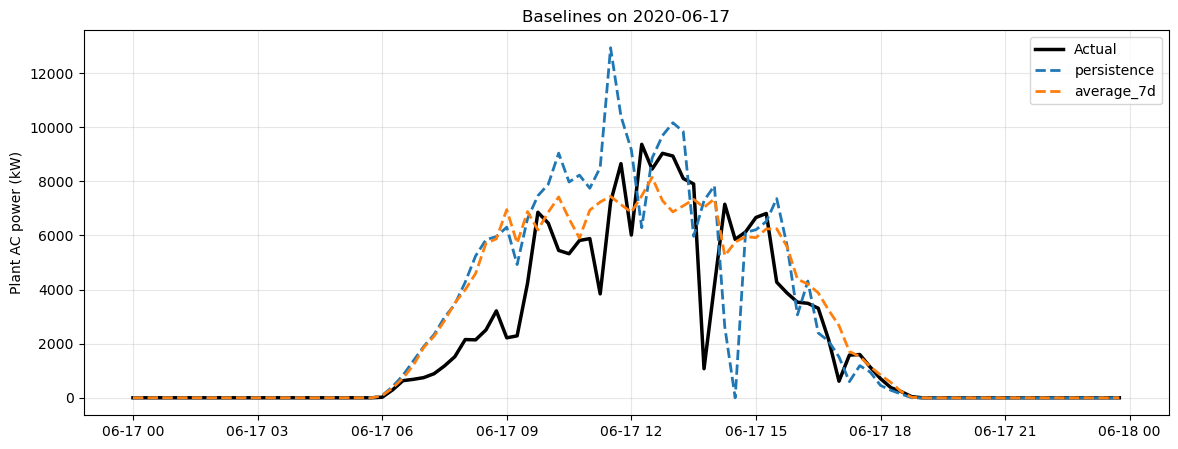

In [7]:
def plot_day(df, columns, title):
    plt.figure(figsize=(14, 5))
    plt.plot(df['ds'], df['y'], color='black', linewidth=2.5, label='Actual')
    for col in columns:
        plt.plot(df['ds'], df[col], linestyle='--', linewidth=2, label=col)
    plt.ylabel('Plant AC power (kW)')
    plt.title(title)
    plt.legend()
    plt.show()

plot_day(test, ['persistence', 'average_7d'], f'Baselines on {test_day}')

> These two numbers are the **bar to clear**. A model that cannot beat them is not worth deploying.


## 4. Prophet

We configure Prophet with what we know about the plant:
- **no weekly or yearly seasonality**: the sun does not care about weekdays, and 34 days cannot show a year;
- a **rigid trend** (`changepoint_prior_scale=0.001`): production should not drift over a month;
- a **detailed daily cycle** (`fourier_order=15`) in **multiplicative** mode: the daily shape scales with the weather.

,MAE (kW),RMSE (kW),nMAE (%),Bias (%)
persistence,1913.8,2506.3,11.9,27.9
average_7d,1380.4,1879.4,8.6,20.9
prophet,1440.5,1923.8,8.9,10.2


In [23]:
def make_prophet(regressor=False):
    m = Prophet(daily_seasonality=True, weekly_seasonality=False, yearly_seasonality=False,
                seasonality_mode='multiplicative'
                #, changepoint_prior_scale=0.001
                )
    # m.add_seasonality(name='daily', period=1, fourier_order=15)
    if regressor:
        m.add_regressor('IRRADIATION')
    return m

prophet = make_prophet()
prophet.fit(train[['ds', 'y']])
test['prophet'] = prophet.predict(test[['ds']])['yhat'].clip(lower=0).values

pd.DataFrame({name: score(test['y'], test[name], test['IRRADIATION'])
              for name in ['persistence', 'average_7d', 'prophet']}).T.round(1)

,MAE (kW),RMSE (kW),nMAE (%),Bias (%)
persistence,1913.8,2506.3,11.9,27.9
average_7d,1380.4,1879.4,8.6,20.9
prophet,1440.5,1923.8,8.9,10.2


### 4.1 Read the components
Prophet's strength is that we can **look inside**: what did it learn?

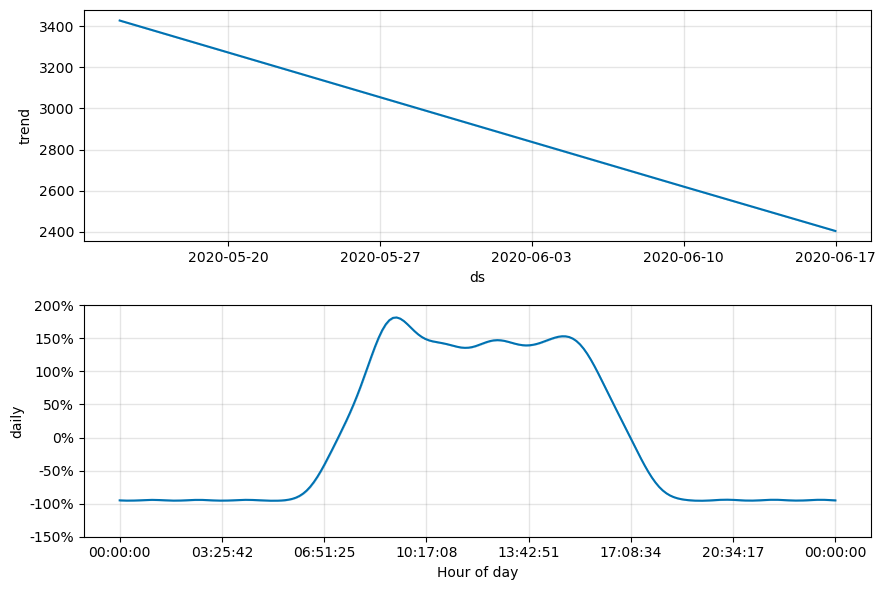

In [24]:
prophet.plot_components(prophet.predict(train[['ds']]))
plt.show()

> Two things to notice:
> - The **trend goes down** over the month. So does the sunshine: in the last week the daily irradiation is about a third lower than in the first (the season is getting cloudier). Without weather data, Prophet can only describe this as a trend.
> - The **daily cycle** peaks in the morning and stays flat around midday, instead of a smooth bell centred at noon. The sun does not flatten at noon: **the outages from Notebook 02 do.** Prophet has learned the plant's failures as if they were part of a normal day. Keep this in mind.

## 5. Adding the weather

From its own past alone, Prophet can only learn the average day. To know about tomorrow's clouds it needs **irradiance** as a regressor.

> ⚠️ **Honest caveat:** in production, tomorrow's irradiance comes from a **weather forecast**, which has its own errors. Here we use the **measured** irradiance of the test day, so this result is an **upper bound**: the best a weather-aware model could do with a perfect weather forecast.

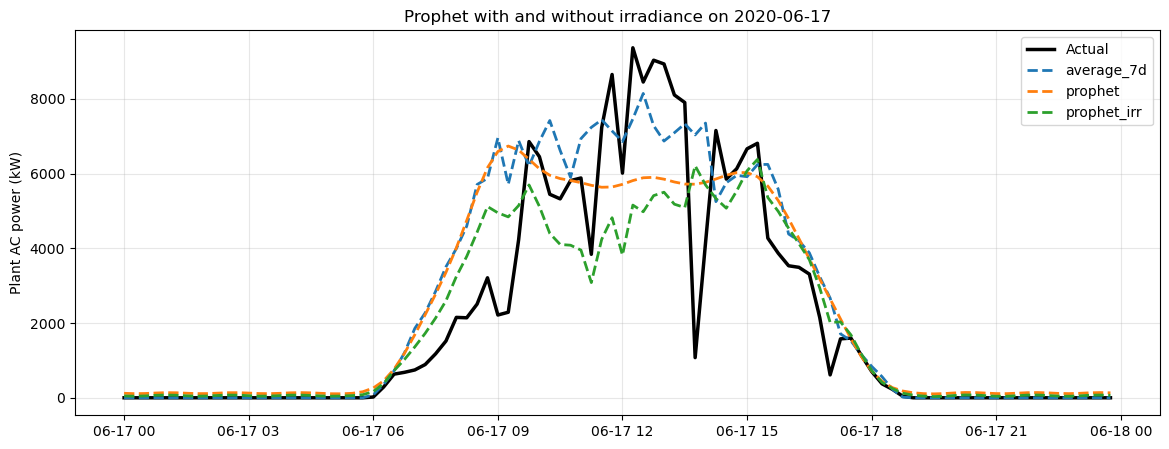

,MAE (kW),RMSE (kW),nMAE (%),Bias (%)
persistence,1913.8,2506.3,11.9,27.9
average_7d,1380.4,1879.4,8.6,20.9
prophet,1440.5,1923.8,8.9,10.2
prophet_irr,1468.9,1909.8,9.1,-6.1


In [11]:
prophet_irr = make_prophet(regressor=True)
prophet_irr.fit(train[['ds', 'y', 'IRRADIATION']])
test['prophet_irr'] = prophet_irr.predict(test[['ds', 'IRRADIATION']])['yhat'].clip(lower=0).values

plot_day(test, ['average_7d', 'prophet', 'prophet_irr'], f'Prophet with and without irradiance on {test_day}')
pd.DataFrame({name: score(test['y'], test[name], test['IRRADIATION'])
              for name in ['persistence', 'average_7d', 'prophet', 'prophet_irr']}).T.round(1)

> On this single day the simple average profile is hard to beat, and irradiance does not even seem to help. But one day is one draw: it can be lucky or unlucky. Before drawing conclusions we need more days.

## 6. Rolling backtest: seven test days

For each of the last 7 days: train on everything before it, forecast that day, score. Exactly what would have happened in real operations, one day at a time.

In [12]:
def forecast_day(train, test, model):
    if model == 'persistence':
        return train[train['ds'].dt.date == train['ds'].dt.date.max()]['y'].values
    if model == 'average_7d':
        recent = train[train['ds'].dt.date > train['ds'].dt.date.max() - pd.Timedelta(days=7)]
        return test['ds'].dt.time.map(recent.groupby(recent['ds'].dt.time)['y'].mean()).values
    m = make_prophet(regressor=(model == 'prophet_irr'))
    cols = ['ds', 'y', 'IRRADIATION'] if model == 'prophet_irr' else ['ds', 'y']
    m.fit(train[cols].dropna(subset=['y']))
    return m.predict(test[cols[:1] + cols[2:]])['yhat'].clip(lower=0).values

def backtest(data, models, n_days=7):
    results = []
    for day in days[-n_days:]:
        train, test = data[data['ds'].dt.date < day], ts[ts['ds'].dt.date == day].copy()
        for model in models:
            test[model] = forecast_day(train, test, model)
        results.append(test)
    return pd.concat(results)

MODELS = ['persistence', 'average_7d', 'prophet', 'prophet_irr']
bt = backtest(ts, MODELS)
summary = pd.DataFrame({m: score(bt['y'], bt[m], bt['IRRADIATION']) for m in MODELS}).T.round(1)
summary

,MAE (kW),RMSE (kW),nMAE (%),Bias (%)
persistence,2000.2,2796.5,12.4,0.4
average_7d,1675.9,2284.8,10.4,-2.8
prophet,1596.1,2179.5,9.9,-10.7
prophet_irr,1465.9,2041.7,9.1,-17.0


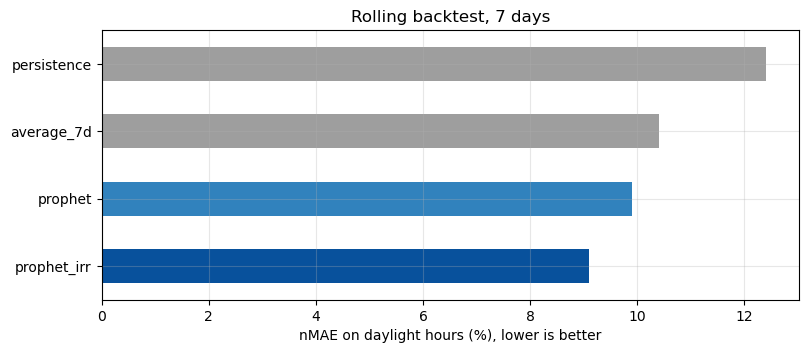

In [13]:
ax = summary['nMAE (%)'].plot(kind='barh', color=['#9e9e9e', '#9e9e9e', '#3182bd', '#08519c'], figsize=(9, 3.5))
ax.invert_yaxis()
ax.set_xlabel('nMAE on daylight hours (%), lower is better')
ax.set_title('Rolling backtest, 7 days')
plt.show()

> Read the table in two directions:
> - **nMAE:** over seven days Prophet beats the baselines, and irradiance helps further. Weather is the key input.
> - **Bias:** the Prophet models **under-forecast**, the weather-aware one the most. The baselines do not, because they only look at the last few days. Why?
>
> Remember the flat midday in the daily cycle. Prophet learned from a month full of outages, while the test week (11–17 June) was almost clean: Notebook 02's heatmap showed it. The model expects the plant to fail at noon, and this week it did not.

## 7. Clean the training data

Prophet is robust to gaps: we can simply **remove the outage moments** from the training data (set them to missing) and retrain. The test days stay exactly as they were.

In [15]:
ts_clean = ts.copy()
ts_clean.loc[ts_clean['inverters_out'] > 0, 'y'] = np.nan
removed = ts_clean['y'].isna()
sunny = ts_clean['IRRADIATION'] > 0.1
print(f"Training readings removed: {removed.sum():,} of {len(ts_clean):,}")
print(f"Average irradiance of removed readings: {ts_clean.loc[removed & sunny, 'IRRADIATION'].mean():.2f} kW/m², "
      f"of kept daylight readings: {ts_clean.loc[~removed & sunny, 'IRRADIATION'].mean():.2f} kW/m²")

bt_clean = backtest(ts_clean, ['prophet', 'prophet_irr'])
summary.loc['prophet (clean training)'] = score(bt_clean['y'], bt_clean['prophet'], bt_clean['IRRADIATION'])
summary.loc['prophet_irr (clean training)'] = score(bt_clean['y'], bt_clean['prophet_irr'], bt_clean['IRRADIATION'])
summary.round(1)

Training readings removed: 589 of 3,264
Average irradiance of removed readings: 0.74 kW/m², of kept daylight readings: 0.38 kW/m²


,MAE (kW),RMSE (kW),nMAE (%),Bias (%)
persistence,2000.2,2796.5,12.4,0.4
average_7d,1675.9,2284.8,10.4,-2.8
prophet,1596.1,2179.5,9.9,-10.7
prophet_irr,1465.9,2041.7,9.1,-17.0
prophet (clean training),1851.2,2599.9,11.5,-15.7
prophet_irr (clean training),827.0,1439.6,5.1,1.6


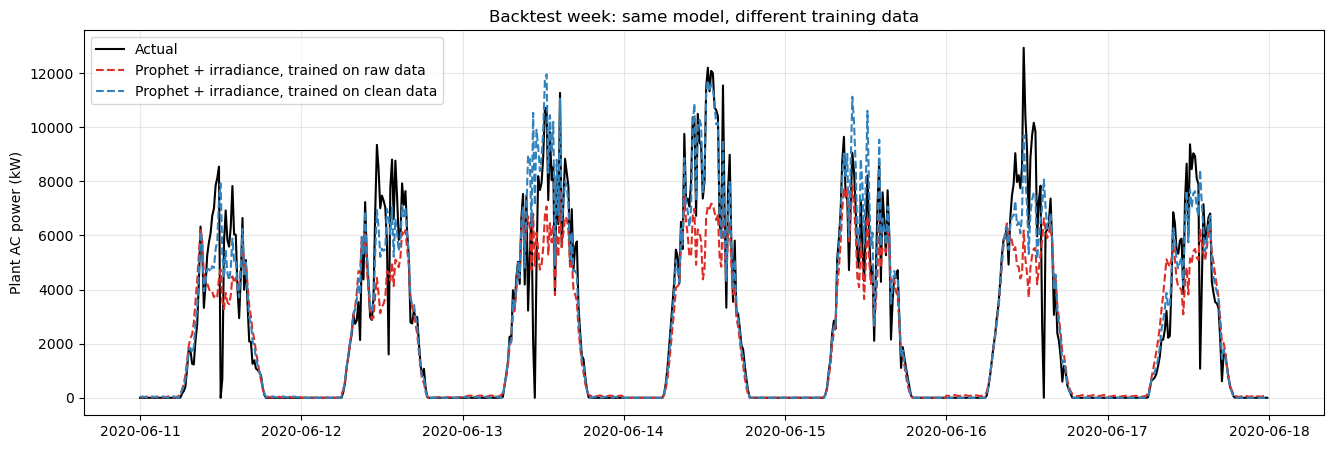

In [16]:
week = bt[['ds', 'y', 'prophet_irr']].assign(clean=bt_clean['prophet_irr'].values)
plt.figure(figsize=(16, 5))
plt.plot(week['ds'], week['y'], color='black', linewidth=1.5, label='Actual')
plt.plot(week['ds'], week['prophet_irr'], color='#de2d26', linestyle='--', label='Prophet + irradiance, trained on raw data')
plt.plot(week['ds'], week['clean'], color='#3182bd', linestyle='--', label='Prophet + irradiance, trained on clean data')
plt.ylabel('Plant AC power (kW)')
plt.title('Backtest week: same model, different training data')
plt.legend()
plt.show()

> Two opposite results, both instructive:
> - **With irradiance**, clean training data roughly **halves the error** and the bias disappears. Same algorithm, same parameters: **only the training data changed.** The model trained on raw data keeps cutting the midday peaks, because it learned that the plant fails at noon.
> - **Without irradiance**, cleaning makes things worse. Outages happen at the sunniest moments, so deleting them leaves a sample that looks cloudier than reality (see the irradiance printed above). A model that knows the irradiance is not fooled; a model that does not, is. **Deleting data is never neutral.**
>
> Remember the caveat: irradiance here is measured, not forecast. With a real weather forecast the errors would be larger, but the lesson on data quality stays the same.

## Wrap-up

| Step | What we learned |
|---|---|
| Baselines | Persistence and the average day set the bar; cheap and hard to beat |
| Prophet | Learns the daily cycle; its components show **what** it learned, including the outages |
| + Irradiance | Weather is the key input; measured irradiance gives an upper bound |
| Backtest | One day can mislead; seven days give a fair picture, bias included |
| Clean training | Removing outages halved the error of the weather-aware model; without weather, deleting data backfired |

**Three lessons for any forecasting project**
1. **Start from baselines** and evaluate like in production: rolling backtest, daylight hours, nMAE and bias.
2. **Read the model, not only the score.** The components told us what was wrong before the metrics did.
3. **Data quality comes first.** The detective work of Notebooks 01–03 is what made the forecast good.